In [3]:
import glob

import numpy as np
import pandas as pd
from skimage import io

from coremdlr import CoreSegmenter

from coremdlr.models_config import mrcnn_model_dir, mrcnn_weights_path

In [5]:
segmenter = CoreSegmenter(mrcnn_model_dir, mrcnn_weights_path) #, model_config=config)

building model
loading weights
Re-starting from epoch 24


In [2]:
test_dir = '/home/administrator/Dropbox/core_data/well_core_data/wos_data/schiehallion-complex/204-19-7/converted/'
depth_df = pd.read_csv(test_dir+'auto_depths_run1.csv')
depth_df

,Unnamed: 0,top,bottom
0,S00116639.jpeg,2131,2132
1,S00116640.jpeg,2132,2134
2,S00116641.jpeg,2134,2136
3,S00116642.jpeg,2136,2138
4,S00116643.jpeg,2138,2140
5,S00116644.jpeg,2140,2142
6,S00116645.jpeg,2142,2144
7,S00116646.jpeg,2144,2146
8,S00116647.jpeg,2146,2148
9,S00116648.jpeg,2148,2150


Processing 1 images
image                    shape: (4731, 7145, 3)       min:    0.00000  max:  255.00000  uint8


/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/transform/_warps.py:110: UserWarning: Anti-aliasing will be enabled by default in skimage 0.15 to avoid aliasing artifacts when down-sampling images.
  warn("Anti-aliasing will be enabled by default in skimage 0.15 to "


molded_images            shape: (1, 1024, 1024, 3)    min: -123.70000  max:  151.10000  float64
image_metas              shape: (1, 14)               min:    0.00000  max: 7145.00000  float64
anchors                  shape: (1, 261888, 4)        min:   -0.45518  max:    1.39262  float32


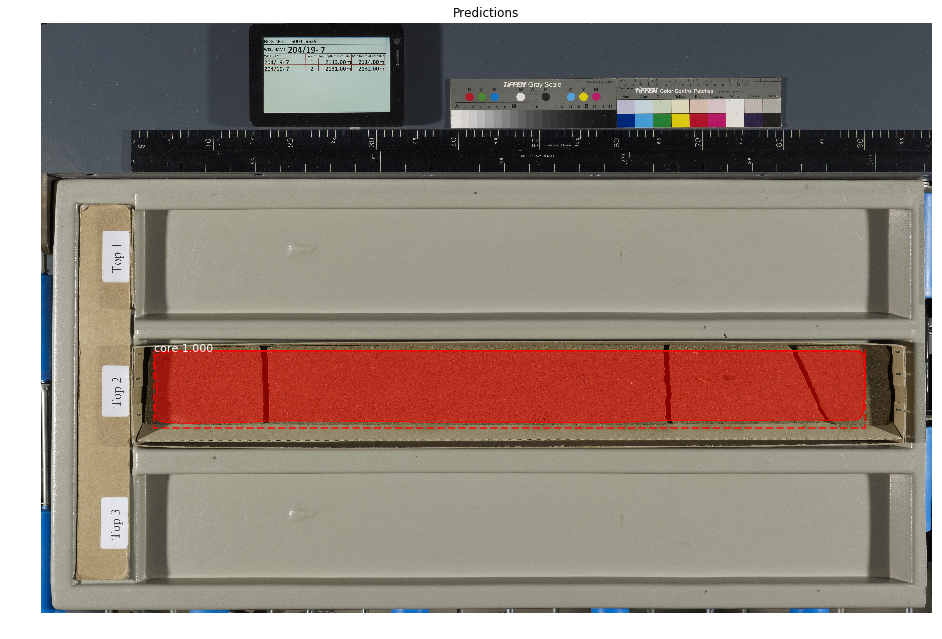

In [19]:
from mrcnn import visualize
import matplotlib.pyplot as plt

def get_ax(rows=1, cols=1, size=16):
    """Return a Matplotlib Axes array to be used in
    all visualizations in the notebook. Provide a
    central point to control graph sizes.
    
    Adjust the size attribute to control how big to render images
    """
    _, ax = plt.subplots(rows, cols, figsize=(size*cols, size*rows))
    return ax

image = io.imread(test_dir + 'S00116639.jpeg')

# Run object detection
results = segmenter.mrcnn.detect([image], verbose=1)

# Display results
ax = get_ax(1)
r = results[0]
visualize.display_instances(image, r['rois'], r['masks'], r['class_ids'], 
                            ['bg', 'core'], r['scores'], ax=ax,
                            title="Predictions")
#log("gt_class_id", gt_class_id)
#log("gt_bbox", gt_bbox)
#log("gt_mask", gt_mask)

In [17]:
tops = depth_df.top.values.astype(float)
bottoms = tops + 2.0

test_files = sorted(glob.glob(test_dir+'*.jpeg'))
cols = [segmenter.segment(f, [t, b]) for f, t, b in zip(test_files, tops, bottoms)]

Reading file: /home/administrator/Dropbox/core_data/well_core_data/wos_data/schiehallion-complex/204-19-7/converted/S00116635.jpeg


/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/transform/_warps.py:110: UserWarning: Anti-aliasing will be enabled by default in skimage 0.15 to avoid aliasing artifacts when down-sampling images.
  warn("Anti-aliasing will be enabled by default in skimage 0.15 to "


Reading file: /home/administrator/Dropbox/core_data/well_core_data/wos_data/schiehallion-complex/204-19-7/converted/S00116636.jpeg
Reading file: /home/administrator/Dropbox/core_data/well_core_data/wos_data/schiehallion-complex/204-19-7/converted/S00116637.jpeg


KeyboardInterrupt: 

In [5]:
from functools import reduce
from operator import add

core_col = reduce(add, cols)
core_col.img.dtype

dtype('uint8')

In [6]:
# trim the bottom
good = np.where(core_col.x_depth < 2221.2)[0]

core_col.x_depth = core_col.x_depth[good]
core_col.img = core_col.img[good,:,:]

In [7]:
core_col.x_depth.shape, core_col.img.shape

((78689,), (78689, 680, 3))

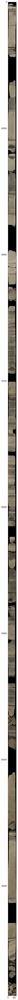

In [8]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(5,100))
ax.imshow(core_col.img)
#plt.yticks(core_col.x_depth)

In [9]:
#from skimage import io
#io.imsave('204-19-6_stacked_img.png', core_col.img)
#np.save('204-19-6_depths.npy', core_col.x_depth)

In [27]:
def make_tick_objects(x_depth, divisor):
    ticks = ['{:.2f}'.format(x_depth[0])]
    locs  = [0]
    remainders = x_depth % divisor
    for i in range(1,remainders.size-1):
        if np.argmin([remainders[i-1],remainders[i],remainders[i+1]]) == 1:
            ticks.append('{:.2f}'.format(x_depth[i]))
            locs.append(i)
    ticks.append('{:.2f}'.format(x_depth[-1]))
    locs.append(remainders.size)
    return ticks, locs    




In [36]:
import matplotlib.ticker as ticker

aspect = core_col.img.shape[1] / core_col.img.shape[0]
fig_height = 400

fig, ax = plt.subplots(figsize=(aspect*fig_height+3,fig_height))

ticks, locs = make_tick_objects(core_col.x_depth, 0.01)

ax.yaxis.set_major_formatter(ticker.FixedFormatter((ticks)))
ax.yaxis.set_major_locator(ticker.FixedLocator((locs)))
ax.imshow(core_col.img)
fig.savefig('/home/administrator/Dropbox/core_data/204-19-6_depth_fig.png')

## Try adding a `striplog`

In [38]:
import striplog
from striplog import Lexicon, Decor, Component, Legend, Interval, Striplog

striplog.__version__

'0.7.3'

In [44]:
facies = {
    's': Component({'lithology': 'sandstone', 'train':'y'}),
    'i': Component({'lithology': 'interbedded', 'train':'y'}),
    'sh': Component({'lithology': 'shale', 'train':'y'}),
    'bs': Component({'lithology': 'sandstone', 'train': 'n'}),
    't': Component({'lithology': 'turbidite', 'train':'y'}),
    'nc': Component({'lithology': 'none', 'train':'n'}),
}
sandstone = Decor({
    'component': facies['s'],
    'colour': 'yellow',
    'hatch': '.',
    'width': '3',
})

interbedded = Decor({
    'component': facies['i'],
    'colour': 'darkseagreen',
    'hatch': '--',
    'width': '2',
})

shale = Decor({
    'component': facies['sh'],
    'colour': 'darkgray',
    'hatch': '-',
    'width': '1',
})

badsand = Decor({
    'component': facies['bs'],
    'colour': 'orange',
    'hatch': '.',
    'width': '3',
})


# Not sure about the best way to do this, probably better
# just to omit those intervals completely.
nocore = Decor({
    'component': facies['nc'],
    'colour': 'white',
    'hatch': '/',
    'width': '5',
})

turbidite = Decor({
    'component': facies['t'],
    'colour': 'green',
    'hatch': 'xxx',
    'width': '3',
})

legend = Legend([sandstone, badsand, interbedded, shale, turbidite, nocore])

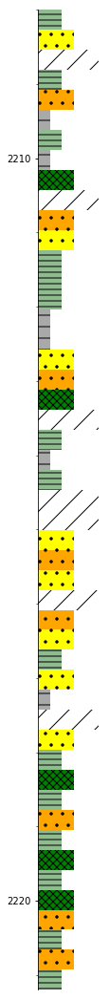

In [53]:
import random

splits = np.linspace(0, core_col.x_depth.size-1, num=50, dtype=np.int)
intervals = []
descrs = list(facies.keys())
for i in range(splits.size-1):
    top = core_col.x_depth[splits[i]]
    base = core_col.x_depth[splits[i+1]]
    descr = random.choice(descrs)
    intervals.append(Interval(top, base=base, description=descr, components=[facies[descr]]))

strip = Striplog(intervals)
strip.plot(legend)




In [114]:
import matplotlib.ticker as ticker

aspect = core_col.img.shape[1] / core_col.img.shape[0]
fig_height = 400

fig, ax = plt.subplots(ncols=2, figsize=(2*aspect*fig_height+3,fig_height))

ticks, locs = make_tick_objects(core_col.x_depth, 0.01)

ax[0].yaxis.set_major_formatter(ticker.FixedFormatter((ticks)))
ax[0].yaxis.set_major_locator(ticker.FixedLocator((locs)))
ax[0].imshow(core_col.img)

#strip.from_csv('/home/administrator/Dropbox/core_data/204-19-6_picks.csv')
#for s in strip:
#    lith = s.data['lithology']
#    s.components = [facies[lith]]
#    s.data = {}

strip_ax = strip.plot(legend, ax=ax[1])
plt.show()

In [60]:
strip.

Striplog(49 Intervals, start=2208.0, stop=2221.1999328802754)

In [78]:
import pandas as pd

df = pd.read_csv('/home/administrator/Dropbox/core_data/204-19-6_picks.csv')

In [79]:
df

,top,base,lithology
0,2208.000,2208.080,nc
1,2208.080,2208.130,sh
2,2208.130,2208.600,s
3,2208.600,2208.630,bs
4,2208.630,2208.690,sh
5,2208.690,2208.730,s
6,2208.730,2209.070,nc
7,2209.070,2209.270,s
8,2209.270,2209.450,sh
9,2209.450,2209.820,s


In [80]:
for i in range(72):
    if df.at[i,'top'] >= df.at[i+1, 'top']:
        print('top: ', df.at[i,'top'])
    if df.at[i,'base'] >= df.at[i+1, 'base']:
        print('base: ', df.at[i,'base'])

In [84]:
for i in range(72):
    if df.at[i,'top'] >= df.at[i+1, 'base']:
        print(i)

In [83]:
for i, litho in enumerate(df.lithology):
    if litho not in facies.keys():
        print(i, litho)

In [96]:
from io import StringIO
import csv

def intervals_from_csv(filename=None,
                 text=None,
                 dlm=',',
                 lexicon=None,
                 points=False,
                 include=None,
                 exclude=None,
                 remap=None,
                 function=None,
                 null=None,
                 ignore=None,
                 source=None,
                 stop=None,
                 fieldnames=None):
        """
        Load from a CSV file or text.
        """
        if (filename is None) and (text is None):
            raise ValueError("You must provide a filename or CSV text.")

        if (filename is not None):
            if source is None:
                source = filename
            with open(filename, 'r') as f:
                text = f.read()

        source = source or 'CSV'

        # Deal with multiple spaces in space delimited file.
        if dlm == ' ':
            text = re.sub(r'[ \t]+', ' ', text)

        if fieldnames is not None:
            text = dlm.join(fieldnames) + '\n' + text

        try:
            f = StringIO(text)  # Python 3
        except TypeError:
            f = StringIO(unicode(text))  # Python 2

        reader = csv.DictReader(f, delimiter=dlm)

        # Reorganize the data to make fixing it easier.
        reorg = {k.strip().lower(): [] for k in reader.fieldnames if k is not None}
        t = f.tell()
        for key in reorg:
            f.seek(t)
            for r in reader:
                s = {k.strip().lower(): v.strip() for k, v in r.items()}
                try:
                    reorg[key].append(float(s[key]))
                except ValueError:
                    reorg[key].append(s[key])

        f.close()

        remap = remap or {}
        for k, v in remap.items():
            reorg[v] = reorg.pop(k)

        data = Striplog._clean_longitudinal_data(reorg, null=null)

        list_of_Intervals = Striplog._build_list_of_Intervals(data,
                                                         points=points,
                                                         lexicon=lexicon,
                                                         include=include,
                                                         exclude=exclude,
                                                         ignore=ignore,
                                                         stop=stop)
        return list_of_Intervals


In [112]:
intervals = from_csv('/home/administrator/Dropbox/core_data/204-19-6_picks.csv')
for i in intervals:
    i.components = [facies[i.data['lithology']]]

In [113]:
strip = Striplog(intervals)

In [100]:
intervals

[Interval({'top': Position({'middle': 2208.0, 'units': 'm'}), 'base': Position({'middle': 2208.08, 'units': 'm'}), 'description': '', 'data': {'lithology': 'nc'}, 'components': []}),
 Interval({'top': Position({'middle': 2208.08, 'units': 'm'}), 'base': Position({'middle': 2208.13, 'units': 'm'}), 'description': '', 'data': {'lithology': 'sh'}, 'components': []}),
 Interval({'top': Position({'middle': 2208.13, 'units': 'm'}), 'base': Position({'middle': 2208.6, 'units': 'm'}), 'description': '', 'data': {'lithology': 's'}, 'components': []}),
 Interval({'top': Position({'middle': 2208.6, 'units': 'm'}), 'base': Position({'middle': 2208.63, 'units': 'm'}), 'description': '', 'data': {'lithology': 'bs'}, 'components': []}),
 Interval({'top': Position({'middle': 2208.63, 'units': 'm'}), 'base': Position({'middle': 2208.69, 'units': 'm'}), 'description': '', 'data': {'lithology': 'sh'}, 'components': []}),
 Interval({'top': Position({'middle': 2208.69, 'units': 'm'}), 'base': Position({'mi

In [103]:
interval = intervals[0]

In [105]:
for interval in intervals:
    if interval.order != 'depth':
        print(interval)

{'top': Position({'middle': 2219.96, 'units': 'm'}), 'base': Position({'middle': 2219.245, 'units': 'm'}), 'description': '', 'data': {'lithology': 'nc'}, 'components': []}


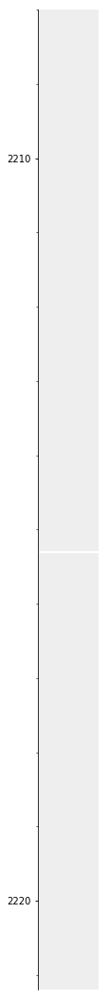

In [111]:
strip.plot()

In [117]:
for r in df.iterrows():
    print(r)

(0, top             2208
base         2208.08
lithology         nc
Name: 0, dtype: object)
(1, top          2208.08
base         2208.13
lithology         sh
Name: 1, dtype: object)
(2, top          2208.13
base          2208.6
lithology          s
Name: 2, dtype: object)
(3, top           2208.6
base         2208.63
lithology         bs
Name: 3, dtype: object)
(4, top          2208.63
base         2208.69
lithology         sh
Name: 4, dtype: object)
(5, top          2208.69
base         2208.73
lithology          s
Name: 5, dtype: object)
(6, top          2208.73
base         2209.07
lithology         nc
Name: 6, dtype: object)
(7, top          2209.07
base         2209.27
lithology          s
Name: 7, dtype: object)
(8, top          2209.27
base         2209.45
lithology         sh
Name: 8, dtype: object)
(9, top          2209.45
base         2209.82
lithology          s
Name: 9, dtype: object)
(10, top          2209.82
base         2209.85
lithology         sh
Name: 10, dtype: objec